# January 2026 GB wind forecast accuracy: analysis

**Question for the day-ahead desk:** when we bid on D-1, how far can we trust the wind forecast, and how much
extra cover should we buy beyond it?

Data: Elexon BMRS `FUELHH` (fuelType = WIND, half-hourly actuals) and `WINDFOR` (hourly forecasts, ~8 runs/day),
target times 1 Jan – 1 Feb 2026, snapshot in `backend/data/`. **Error = forecast − actual**, so a positive error means
the forecast was too high and the desk would have been *short*.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
DATA = Path("../backend/data")

actuals = pd.DataFrame(json.loads((DATA / "actuals.json").read_text()))
forecasts = pd.DataFrame(json.loads((DATA / "forecasts.json").read_text()))
actuals["startTime"] = pd.to_datetime(actuals.startTime, utc=True)
for c in ("startTime", "publishTime"):
    forecasts[c] = pd.to_datetime(forecasts[c], utc=True)

# Every (forecast run, target hour) pair joined with what actually happened.
m = forecasts.merge(actuals, on="startTime", suffixes=("_fc", "_act"))
m["lead_h"] = (m.startTime - m.publishTime).dt.total_seconds() / 3600
m["error"] = m.generation_fc - m.generation_act
m = m[m.lead_h.between(0, 48)]
print(f"{len(actuals)} half-hourly actuals, {forecasts.publishTime.nunique()} forecast runs, {len(m)} matched pairs")

1536 half-hourly actuals, 272 forecast runs, 12256 matched pairs


## 1. Accuracy decays with lead time, but slowly

In [2]:
bins = [0, 6, 12, 18, 24, 30, 36, 42, 48]
g = m.groupby(pd.cut(m.lead_h, bins, include_lowest=True), observed=True).error
table = pd.DataFrame({
    "MAE (MW)": g.apply(lambda e: e.abs().mean()),
    "RMSE (MW)": g.apply(lambda e: np.sqrt((e**2).mean())),
    "Bias (MW)": g.mean(),
    "P90 over-forecast (MW)": g.quantile(0.9),
    "n": g.size(),
}).round(0)
table

,MAE (MW),RMSE (MW),Bias (MW),P90 over-forecast (MW),n
lead_h,,,,,
"(-0.001, 6.0]",1738.0,2221.0,1519.0,3714.0,1536
"(6.0, 12.0]",1799.0,2274.0,1587.0,3808.0,1536
"(12.0, 18.0]",1897.0,2384.0,1707.0,3900.0,1536
"(18.0, 24.0]",2007.0,2495.0,1844.0,4032.0,1536
"(24.0, 30.0]",2028.0,2500.0,1801.0,4106.0,1536
"(30.0, 36.0]",2119.0,2597.0,1794.0,4307.0,1536
"(36.0, 42.0]",2214.0,2736.0,1915.0,4394.0,1536
"(42.0, 48.0]",2372.0,2920.0,2023.0,4585.0,1504


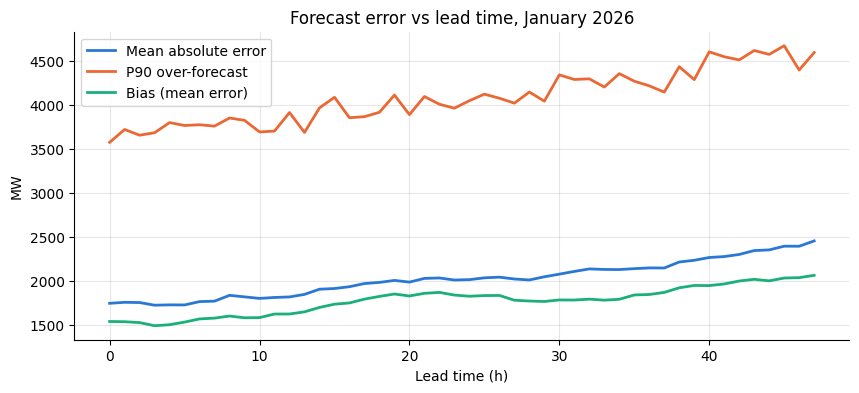

In [3]:
prof = m.assign(h=np.floor(m.lead_h)).groupby("h").error
fig, ax = plt.subplots()
ax.plot(prof.apply(lambda e: e.abs().mean()), color=BLUE, lw=2, label="Mean absolute error")
ax.plot(prof.quantile(0.9), color=ORANGE, lw=2, label="P90 over-forecast")
ax.plot(prof.mean(), color=AQUA, lw=2, label="Bias (mean error)")
ax.set(xlabel="Lead time (h)", ylabel="MW", title="Forecast error vs lead time, January 2026"); ax.legend();

**Takeaway:** MAE rises from ~1.7 GW (0–6 h) to ~2.3 GW (36–48 h). A typical D-1 decision is 15–39 h ahead,
so the desk works at roughly 1.9–2.1 GW MAE. Most of that MAE is **bias**, not noise: the forecast is
consistently too high at every lead time.

## 2. Why is the forecast biased high? A curtailment signature

In [4]:
lvl = m.groupby(pd.cut(m.generation_fc, [0, 4000, 8000, 12000, 16000, 20000, 26000]), observed=True).error
lvl_table = pd.DataFrame({"mean error (MW)": lvl.mean().round(0), "n": lvl.size()})
print(f"Max actual: {actuals.generation.max():,} MW | max forecast: {forecasts.generation.max():,} MW")
lvl_table

Max actual: 17,805 MW | max forecast: 21,353 MW


,mean error (MW),n
generation_fc,,
"(0, 4000]",881.0,148
"(4000, 8000]",532.0,2089
"(8000, 12000]",1101.0,3306
"(12000, 16000]",1435.0,2012
"(16000, 20000]",2684.0,3981
"(20000, 26000]",4552.0,720


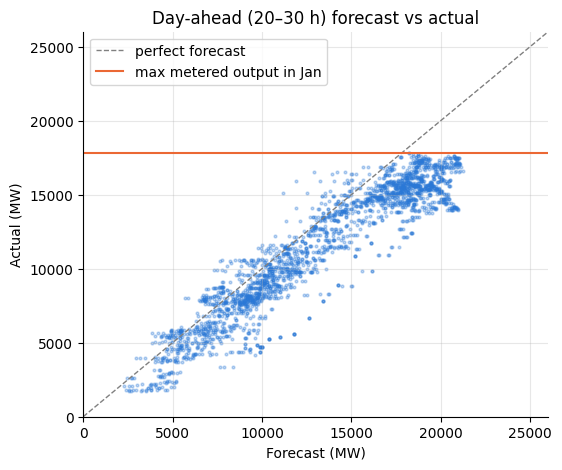

In [5]:
sample = m[m.lead_h.between(20, 30)]
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample.generation_fc, sample.generation_act, s=4, alpha=0.3, color=BLUE)
lim = [0, 26000]; ax.plot(lim, lim, color="grey", lw=1, ls="--", label="perfect forecast")
ax.axhline(actuals.generation.max(), color=ORANGE, lw=1.5, label="max metered output in Jan")
ax.set(xlim=lim, ylim=lim, xlabel="Forecast (MW)", ylabel="Actual (MW)", title="Day-ahead (20–30 h) forecast vs actual")
ax.legend();

**Takeaway:** at low wind the forecast is close (bias ~0.5–0.9 GW). Above ~16 GW forecast, actual output flattens
at ~17–18 GW while forecasts go above 21 GW, leaving an average gap of **4.5 GW** whenever the forecast exceeds 20 GW. This is what network constraints and
**curtailment** look like: wind *was* there, but transmission-metered output was turned down. `WINDFOR` forecasts
unconstrained potential. Implication for the desk: **on high-wind days, discount the forecast heavily.**

## 3. What the desk actually saw: forecast available at 09:00 on D-1

In [6]:
def day_ahead_view(cutoff="09:00"):
    df = forecasts.copy()
    uk = df.startTime.dt.tz_convert("Europe/London")
    decision = (uk.dt.normalize() - pd.Timedelta(days=1) + pd.Timedelta(cutoff + ":00")).dt.tz_convert("UTC")
    df = df[df.publishTime <= decision]
    latest = df.sort_values("publishTime").groupby("startTime").tail(1)
    out = latest.merge(actuals, on="startTime", suffixes=("_fc", "_act"))
    out["error"] = out.generation_fc - out.generation_act
    return out.sort_values("startTime")

da = day_ahead_view()
e = da.error
summary = pd.Series({
    "hours": len(e), "MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean()), "bias": e.mean(),
    "P10 error": e.quantile(0.1), "P50 error": e.median(), "P90 over-forecast": e.quantile(0.9),
    "P95 over-forecast": e.quantile(0.95), "share of hours forecast too high": (e > 0).mean(),
}).round(2)
summary

hours                                768.00
MAE                                 2091.24
RMSE                                2571.53
bias                                1823.35
P10 error                           -406.20
P50 error                           1637.50
P90 over-forecast                   4250.80
P95 over-forecast                   5333.05
share of hours forecast too high       0.85
dtype: float64

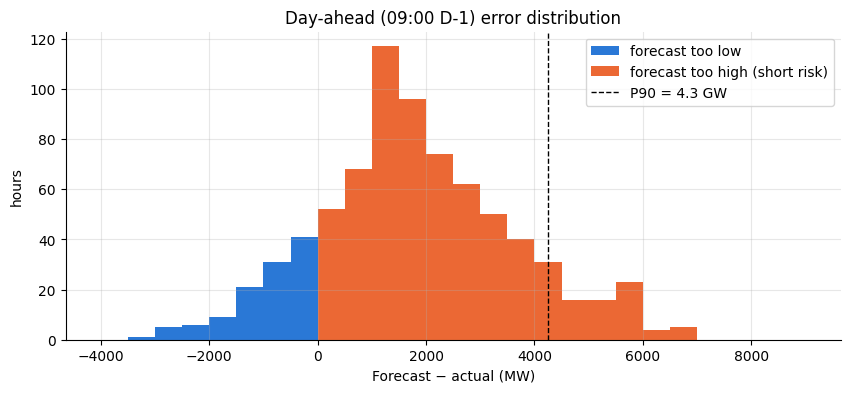

In [7]:
fig, ax = plt.subplots()
ax.hist(e[e < 0], bins=np.arange(-4000, 0.1, 500), color=BLUE, label="forecast too low")
ax.hist(e[e >= 0], bins=np.arange(0, 9001, 500), color=ORANGE, label="forecast too high (short risk)")
ax.axvline(e.quantile(0.9), color="black", ls="--", lw=1, label=f"P90 = {e.quantile(0.9)/1000:.1f} GW")
ax.set(xlabel="Forecast − actual (MW)", ylabel="hours", title="Day-ahead (09:00 D-1) error distribution"); ax.legend();

**Takeaway:** in 85% of hours the D-1 forecast was too high. To be covered in 90% of hours, the desk would have
needed to procure ~**4.3 GW** more than the raw wind forecast implied (P90 over-forecast). The dashboard shows this
"safety buffer" for any date range and decision time.

## 4. Could a simple bias correction help?
An honest, out-of-sample test: for each delivery day D, subtract the mean error of the **previous 7 days' worth of
target hours already settled before the 09:00 D-1 decision**. No look-ahead.

In [8]:
da["decision"] = (da.startTime.dt.tz_convert("Europe/London").dt.normalize() - pd.Timedelta(hours=15)).dt.tz_convert("UTC")
corr = []
for dec, grp in da.groupby("decision"):
    hist = da[(da.startTime < dec) & (da.startTime >= dec - pd.Timedelta(days=7))]
    corr.append(grp.assign(adj=hist.error.mean() if len(hist) >= 48 else np.nan))
c = pd.concat(corr).dropna(subset=["adj"])
c["err_corrected"] = c.error - c.adj
pd.DataFrame({
    "raw forecast": [c.error.abs().mean(), c.error.mean(), c.error.quantile(0.9)],
    "bias-corrected": [c.err_corrected.abs().mean(), c.err_corrected.mean(), c.err_corrected.quantile(0.9)],
}, index=["MAE", "bias", "P90 over-forecast"]).round(0)

,raw forecast,bias-corrected
MAE,1984.0,1629.0
bias,1688.0,-129.0
P90 over-forecast,4152.0,2973.0


**Takeaway:** even this naive correction removes almost all of the bias, cuts MAE by ~18% (≈2.0 → 1.6 GW) and shrinks
the P90 safety buffer from ~4.2 to ~3.0 GW. That is over 1 GW less reserve to buy in a typical hour. A correction
conditioned on forecast level (Section 2) should do better still. This is the headline *phase-2* proposal.

## 5. When in the day is the forecast least reliable?

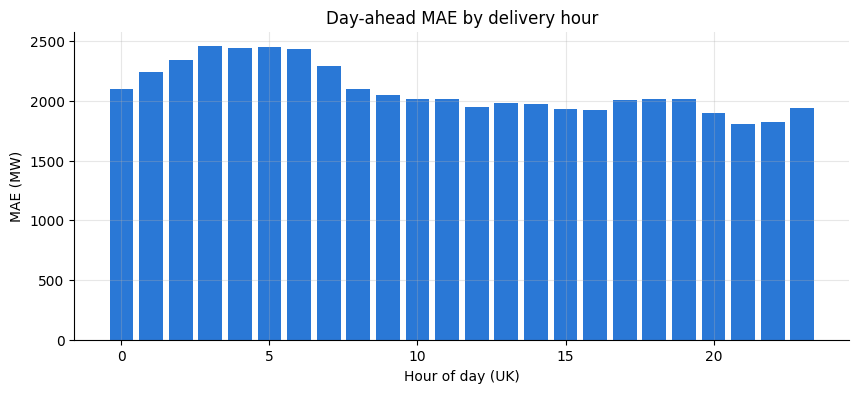

In [9]:
hod = da.groupby(da.startTime.dt.tz_convert("Europe/London").dt.hour).error
fig, ax = plt.subplots()
ax.bar(hod.mean().index, hod.apply(lambda x: x.abs().mean()), color=BLUE, width=0.8)
ax.set(xlabel="Hour of day (UK)", ylabel="MAE (MW)", title="Day-ahead MAE by delivery hour");

## 6. How much wind can the desk rely on at all?

P95 (exceeded 95% of time)      4.4 GW
P90 (exceeded 90% of time)     5.43 GW
P50 (exceeded 50% of time)    11.74 GW
P10 (exceeded 10% of time)     16.4 GW
Name: generation, dtype: object


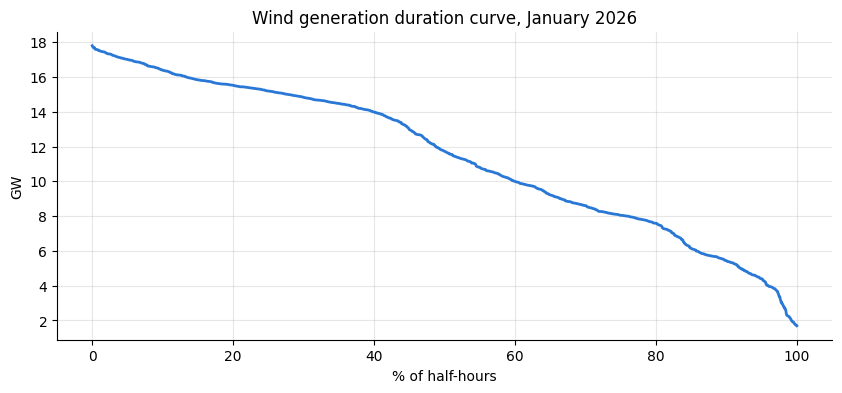

In [10]:
q = actuals.generation.quantile([0.05, 0.1, 0.5, 0.9]).rename(lambda x: f"P{int(round((1 - x) * 100))} (exceeded {int(round((1-x)*100))}% of time)")
print((q / 1000).round(2).astype(str) + " GW")
fig, ax = plt.subplots()
ax.plot(np.linspace(0, 100, len(actuals)), np.sort(actuals.generation)[::-1] / 1000, color=BLUE, lw=2)
ax.set(xlabel="% of half-hours", ylabel="GW", title="Wind generation duration curve, January 2026");

## Conclusions for the pilot

1. **Error grows with lead time** (~1.7 GW MAE intraday → ~2.3 GW at 48 h). D-1 decisions sit at ~2 GW MAE.
2. **The forecast is systematically high** (+1.5 to +2 GW) and the gap is **largest on windy days**, consistent with
   curtailment. The raw forecast should not be used one-for-one when sizing purchases.
3. **Safety buffer:** for January, covering 90% of hours needed ~4.3 GW on top of the 09:00 D-1 forecast.
4. **Floor:** at least ~5.4 GW of wind was available 90% of the time; ~1.7 GW was the absolute minimum.
5. **Quick win:** a trailing 7-day bias correction cut D-1 MAE by ~18% and the P90 buffer by ~1.2 GW.
6. Next steps: extend history (seasonality), add level-dependent bias correction, and add live data refresh.